<a href="https://colab.research.google.com/github/contemplator/nchu-research-method-traffic-violation-dataset/blob/main/notebooks/NCHU_Research_YOLOv7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **國立中興大學 研究方法 (Research Methodology) - 期末專案**
## **Part 2: YOLOv7 台灣市區交通違規即時偵測與消融研究**

---
### 📌 **專案基本資訊**
* **專題題目**：基於 YOLOv7 深度學習之台灣多類別交通違規停車即時偵測與動態影片分析
* **繳交期限 (Deadline)**：**2026/12/17**
* **成果繳交格式**：`{StudentID1}_{StudentID2}_{StudentID3}.zip`（含報告 Slides / 文件）
* **4 大違規標註類別 (Target Classes)**：
  0. `red_line_parking` (紅線違規停車)
  1. `double_parking` (並排違規停車)
  2. `yellow_box_parking` (黃網線臨時暫停)
  3. `sidewalk_parking` (人行道/騎樓違停)

* **模型倉庫**：`contemplator/nchu-research-method-traffic-violation-model`
* **資料/實驗倉庫**：`contemplator/nchu-research-method-traffic-violation-dataset`

# **Step 1: 環境檢查與 GPU 配置 (Environment Checking)**

In [1]:
!nvidia-smi
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Current Device: {torch.cuda.get_device_name(0)}")

Thu Oct 15 05:32:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# **Step 2: 掛載 Google 雲端硬碟 (Mount Google Drive)**

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


# **Step 3: 下載專案倉庫與安裝 YOLOv7 依賴 (Setup YOLOv7)**
> 若為 Private 倉庫，可填寫您的 GitHub Personal Access Token (PAT) 以便免密碼 Clone。

In [5]:
%cd /content
!mkdir -p workspace
%cd /content/workspace

# Clone 倉庫 (若已存在加上判斷避免報錯)
![ ! -d "yolov7" ] && git clone https://github.com/contemplator/nchu-research-method-traffic-violation-model.git yolov7
![ ! -d "dataset_repo" ] && git clone https://github.com/contemplator/nchu-research-method-traffic-violation-dataset.git dataset_repo
!ln -sfn /content/workspace/dataset_repo /content/workspace/nchu-research-method-traffic-violation-dataset

# 進入 yolov7 並只安裝 Colab 缺少的套件 (避免降級 numpy 造成編譯失敗)
%cd /content/workspace/yolov7
!pip install thop albumentations


/content
/content/workspace
/content/workspace/yolov7


## **下載官方預訓練權重 (Pretrained Weights)**

In [6]:
%cd /content/workspace/yolov7
!wget -P /content/workspace/yolov7 https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7-tiny.pt
!wget -P /content/workspace/yolov7 https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7.pt

/content/workspace/yolov7
--2026-10-15 06:18:00--  https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7-tiny.pt
Resolving github.com (github.com)... 140.82.112.3
Connecting to github.com (github.com)|140.82.112.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/511187726/ba7d01ee-125a-4134-8864-fa1abcbf94d5?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-15T07%3A02%3A31Z&rscd=attachment%3B+filename%3Dyolov7-tiny.pt&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-15T06%3A01%3A44Z&ske=2026-10-15T07%3A02%3A31Z&sks=b&skv=2018-11-09&sig=631ZykpOIAdHJxjFgbSaxrqxnIWg6uoaySzAdR%2Fdjzk%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MjA0Njg4MSwibmJmIjoxNzkyMDQ1MDgxLCJwYXRoIjoicmVsZWFzZWFz

# **Step 4: 準備資料集 (Dataset Preparation)**
將本地打包切分好的 `dataset.zip` 自 Google Drive 解壓縮至工作區：

In [7]:
import os
# 請確認 Drive 上的 zip 路徑是否正確 (例如 Drive 中的 NCHU_YOLO_Project/dataset.zip)
DRIVE_DATASET_ZIP = "/content/drive/MyDrive/NCHU_YOLO_Project/dataset.zip"
TARGET_DATA_DIR = "/content/workspace/dataset_repo/data"

if os.path.exists(DRIVE_DATASET_ZIP):
    !unzip -o -q {DRIVE_DATASET_ZIP} -d {TARGET_DATA_DIR}
    print("✅ 資料集自 Google Drive 解壓縮完成！")
    !ls -la /content/workspace/dataset_repo/data/dataset
else:
    print(f"⚠️ 尚未在 {DRIVE_DATASET_ZIP} 找到壓縮檔，若資料已存在於 dataset_repo 中則可直接使用。")

# 檢查 data.yaml
!cat /content/workspace/dataset_repo/configs/traffic_violation.yaml

✅ 資料集自 Google Drive 解壓縮完成！
total 20
drwxr-xr-x 5 root root 4096 Oct 15 03:54 .
drwxr-xr-x 4 root root 4096 Oct 15 06:18 ..
-rw-r--r-- 1 root root    0 Oct  6 07:25 .gitkeep
drwxr-xr-x 4 root root 4096 Oct 15 03:54 test
drwxr-xr-x 4 root root 4096 Oct 15 03:54 train
drwxr-xr-x 4 root root 4096 Oct 15 03:54 val
# NCHU Research Method - Taiwan Traffic Violation Dataset Config
# 4 Classes: red_line_parking, double_parking, yellow_box_parking, sidewalk_parking

# Dataset paths: Relative to execution directory or absolute paths
# When training in yolov7 directory, paths point to dataset repo:
train: ../nchu-research-method-traffic-violation-dataset/data/dataset/train/images
val: ../nchu-research-method-traffic-violation-dataset/data/dataset/val/images
test: ../nchu-research-method-traffic-violation-dataset/data/dataset/test/images

# Number of classes
nc: 4

# Class names
names: ['red_line_parking', 'double_parking', 'yellow_box_parking', 'sidewalk_parking']


# **Step 5: 4 組消融實驗訓練 (Ablation Experiments)**

| 組別 | 模型架構 | Epochs | Batch | 目的與探討目標 |
| :---: | :--- | :---: | :---: | :--- |
| **Exp 1** | YOLOv7-tiny | 50 | 16 | 輕量輕量模型基準線 (Baseline) |
| **Exp 2** | YOLOv7 Base | 50 | 8 | 骨幹模型尺度對複雜遮擋與小目標效益 |
| **Exp 3** | YOLOv7-tiny | 100 | 16 | 延長訓練週期之充分收斂性與過擬合檢視 |
| **Exp 4** | YOLOv7-tiny (Tuned) | 100 | 16 | 超參數調校 (Mosaic 增強 + 學習率微調) |

### **🔥 Exp 1: YOLOv7-tiny 輕量基準線 (50 Epochs)**

> 加入區塊引述符號



In [12]:
import os

patch_code = """import torch
_orig_load = torch.load
torch.load = lambda *args, **kwargs: _orig_load(*args, **{**kwargs, 'weights_only': False})
"""

for fname in ['train.py', 'test.py', 'detect.py']:
    fpath = os.path.join('/content/workspace/yolov7', fname)
    if os.path.exists(fpath):
        with open(fpath, 'r', encoding='utf-8') as f:
            content = f.read()
        if 'weights_only' not in content:
            with open(fpath, 'w', encoding='utf-8') as f:
                f.write(patch_code + content)

print("✅ PyTorch 2.6 相容性修補完成！")


✅ PyTorch 2.6 相容性修補完成！


In [14]:
# 停用 wandb 互動提示
%env WANDB_MODE=disabled

%cd /content/workspace/yolov7
!python train.py \
  --workers 4 \
  --device 0 \
  --batch-size 16 \
  --epochs 50 \
  --data /content/workspace/dataset_repo/configs/traffic_violation.yaml \
  --img 640 640 \
  --cfg /content/workspace/dataset_repo/configs/yolov7-tiny-custom.yaml \
  --weights yolov7-tiny.pt \
  --name exp1_yolov7_tiny_baseline \
  --hyp data/hyp.scratch.tiny.yaml


env: WANDB_MODE=disabled
/content/workspace/yolov7
I0000 00:00:1792045780.335022   15788 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792045782.544808   15788 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
YOLOR 🚀 a207844 torch 2.11.0+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Namespace(weights='yolov7-tiny.pt', cfg='/content/workspace/dataset_repo/configs/yolov7-tiny-custom.yaml', data='/content/workspace/dataset_repo/configs/traffic_violation.yaml', hyp='data/hyp.scratch.tiny.yaml', epochs=50, batch_size=16, img_size=[640, 640], rect=False, resume=False, nosave=False, notest=False, noautoanchor=False, evolve=False, bucket='', cache_images=False, image_weights=False, device='0', multi_scale=False, single_cls=False, adam=F

### **🔥 Exp 2: YOLOv7 Base 尺度對比 (50 Epochs)**

In [17]:
%cd /content/workspace/yolov7
!python train.py \
  --workers 4 \
  --device 0 \
  --batch-size 8 \
  --epochs 50 \
  --data /content/workspace/dataset_repo/configs/traffic_violation.yaml \
  --img 640 640 \
  --cfg cfg/training/yolov7.yaml \
  --weights yolov7.pt \
  --name exp2_yolov7_base_scale \
  --hyp data/hyp.scratch.p5.yaml

env: WANDB_MODE=disabled
/content/workspace/yolov7
I0000 00:00:1792046048.128509   17028 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792046050.510522   17028 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
YOLOR 🚀 a207844 torch 2.11.0+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Namespace(weights='yolov7.pt', cfg='cfg/training/yolov7.yaml', data='/content/workspace/dataset_repo/configs/traffic_violation.yaml', hyp='data/hyp.scratch.p5.yaml', epochs=50, batch_size=8, img_size=[640, 640], rect=False, resume=False, nosave=False, notest=False, noautoanchor=False, evolve=False, bucket='', cache_images=False, image_weights=False, device='0', multi_scale=False, single_cls=False, adam=False, sync_bn=False, local_rank=-1, workers=4, 

### **🔥 Exp 3: 充分收斂週期對比 (100 Epochs)**

In [18]:
%cd /content/workspace/yolov7
!python train.py \
  --workers 4 \
  --device 0 \
  --batch-size 16 \
  --epochs 100 \
  --data /content/workspace/dataset_repo/configs/traffic_violation.yaml \
  --img 640 640 \
  --cfg /content/workspace/dataset_repo/configs/yolov7-tiny-custom.yaml \
  --weights yolov7-tiny.pt \
  --name exp3_yolov7_tiny_100ep \
  --hyp data/hyp.scratch.tiny.yaml

/content/workspace/yolov7
I0000 00:00:1792046384.329614   18558 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792046386.873174   18558 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
YOLOR 🚀 a207844 torch 2.11.0+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Namespace(weights='yolov7-tiny.pt', cfg='/content/workspace/dataset_repo/configs/yolov7-tiny-custom.yaml', data='/content/workspace/dataset_repo/configs/traffic_violation.yaml', hyp='data/hyp.scratch.tiny.yaml', epochs=100, batch_size=16, img_size=[640, 640], rect=False, resume=False, nosave=False, notest=False, noautoanchor=False, evolve=False, bucket='', cache_images=False, image_weights=False, device='0', multi_scale=False, single_cls=False, adam=False, sync_bn=False, loc

### **🔥 Exp 4: 超參數與資料增強微調 (Custom Hyp + 100 Epochs)**

In [19]:
%cd /content/workspace/yolov7
!python train.py \
  --workers 4 \
  --device 0 \
  --batch-size 16 \
  --epochs 100 \
  --data /content/workspace/dataset_repo/configs/traffic_violation.yaml \
  --img 640 640 \
  --cfg /content/workspace/dataset_repo/configs/yolov7-tiny-custom.yaml \
  --weights yolov7-tiny.pt \
  --name exp4_yolov7_tiny_tuned \
  --hyp /content/workspace/dataset_repo/configs/hyp.scratch.custom.yaml

/content/workspace/yolov7
I0000 00:00:1792046601.804932   19562 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792046604.090676   19562 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
YOLOR 🚀 a207844 torch 2.11.0+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Namespace(weights='yolov7-tiny.pt', cfg='/content/workspace/dataset_repo/configs/yolov7-tiny-custom.yaml', data='/content/workspace/dataset_repo/configs/traffic_violation.yaml', hyp='/content/workspace/dataset_repo/configs/hyp.scratch.custom.yaml', epochs=100, batch_size=16, img_size=[640, 640], rect=False, resume=False, nosave=False, notest=False, noautoanchor=False, evolve=False, bucket='', cache_images=False, image_weights=False, device='0', multi_scale=False, single_cls=

# **Step 6: 測試集獨立指標評估 (Test Evaluation)**

In [20]:
%cd /content/workspace/yolov7
# 評估 Exp 4 於測試集 (test split) 之表現
!python test.py \
  --data /content/workspace/dataset_repo/configs/traffic_violation.yaml \
  --img 640 \
  --batch 16 \
  --conf 0.001 \
  --iou 0.65 \
  --device 0 \
  --weights runs/train/exp4_yolov7_tiny_tuned/weights/best.pt \
  --name exp4_test_evaluation

/content/workspace/yolov7
Namespace(weights=['runs/train/exp4_yolov7_tiny_tuned/weights/best.pt'], data='/content/workspace/dataset_repo/configs/traffic_violation.yaml', batch_size=16, img_size=640, conf_thres=0.001, iou_thres=0.65, task='val', device='0', single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project='runs/test', name='exp4_test_evaluation', exist_ok=False, no_trace=False, v5_metric=False)
YOLOR 🚀 a207844 torch 2.11.0+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Fusing layers... 
IDetect.fuse
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Model Summary: 208 layers, 6015714 parameters, 0 gradients, 13.0 GFLOPS
 Convert model to Traced-model... 
 tr

# **Step 7: 影像與動態行車記錄器影片推論 (Inference)**

In [21]:
%cd /content/workspace/yolov7

# 1. 測試集圖片推論
!python detect.py \
  --weights runs/train/exp4_yolov7_tiny_tuned/weights/best.pt \
  --conf 0.25 \
  --img-size 640 \
  --source /content/workspace/dataset_repo/data/dataset/test/images/ \
  --name detect_test_images

# 2. 行車記錄器影片推論 (若有提供 sample_videos/dashcam.mp4)
VIDEO_PATH = "/content/workspace/dataset_repo/sample_videos/dashcam_nchu.mp4"
if os.path.exists(VIDEO_PATH):
    !python detect.py \
      --weights runs/train/exp4_yolov7_tiny_tuned/weights/best.pt \
      --conf 0.35 \
      --img-size 640 \
      --source {VIDEO_PATH} \
      --name detect_video_dashcam

/content/workspace/yolov7
Namespace(weights=['runs/train/exp4_yolov7_tiny_tuned/weights/best.pt'], source='/content/workspace/dataset_repo/data/dataset/test/images/', img_size=640, conf_thres=0.25, iou_thres=0.45, device='', view_img=False, save_txt=False, save_conf=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project='runs/detect', name='detect_test_images', exist_ok=False, no_trace=False)
YOLOR 🚀 a207844 torch 2.11.0+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Fusing layers... 
IDetect.fuse
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Model Summary: 208 layers, 6015714 parameters, 0 gradients, 13.0 GFLOPS
 Convert model to Traced-model... 
 traced_script_module saved! 
 model is tra

# **Step 8: 成果圖表視覺化 (Visualizations)**

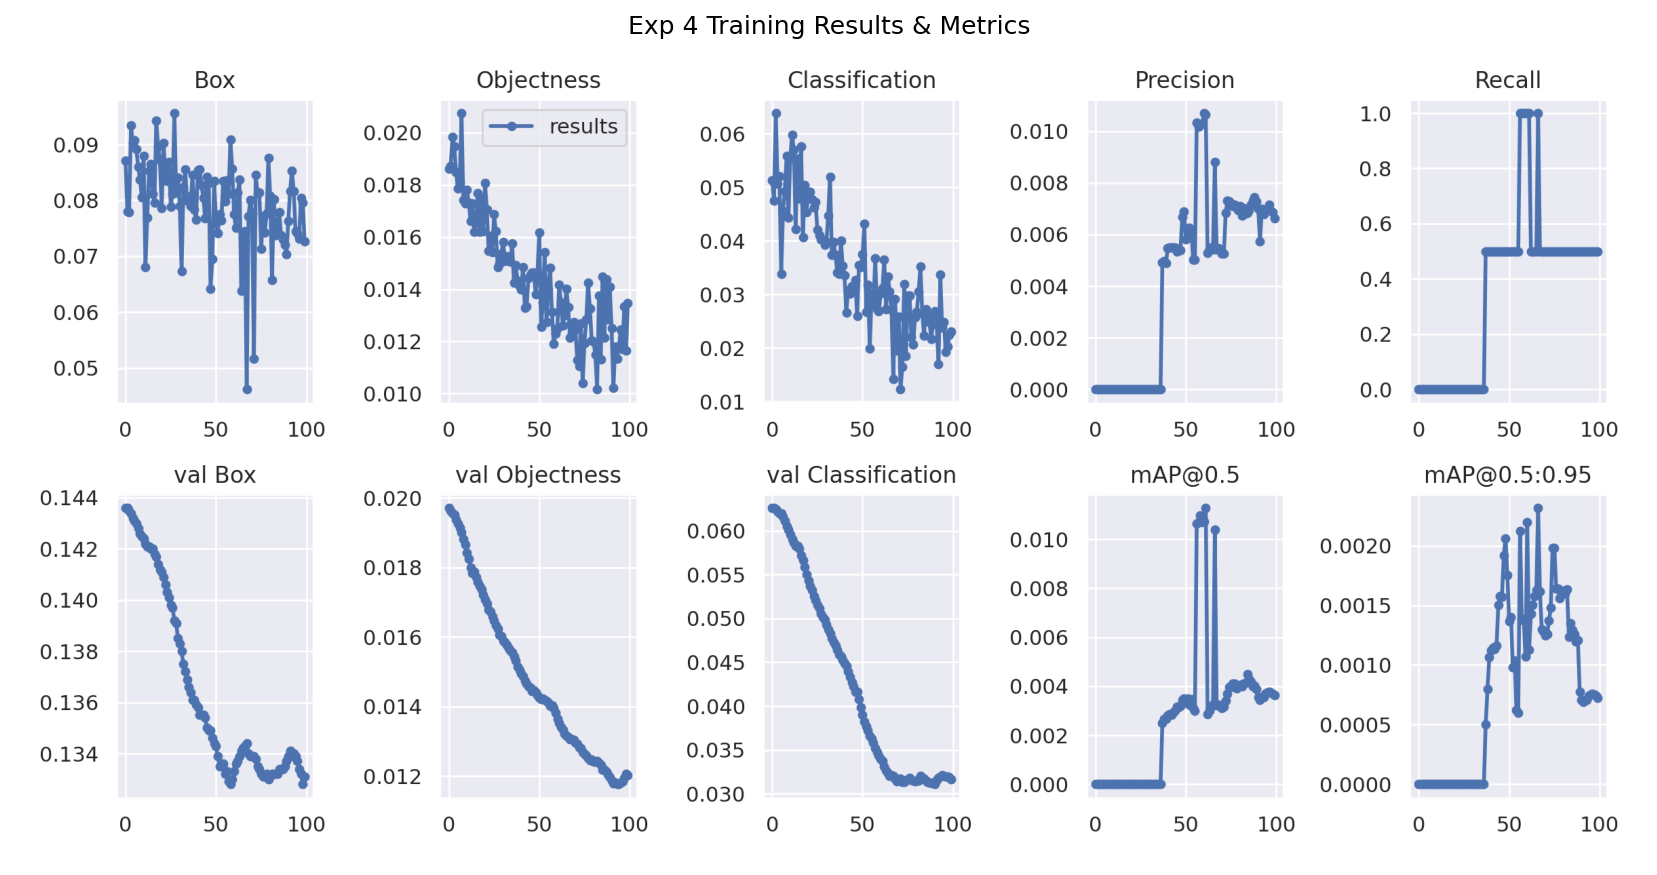

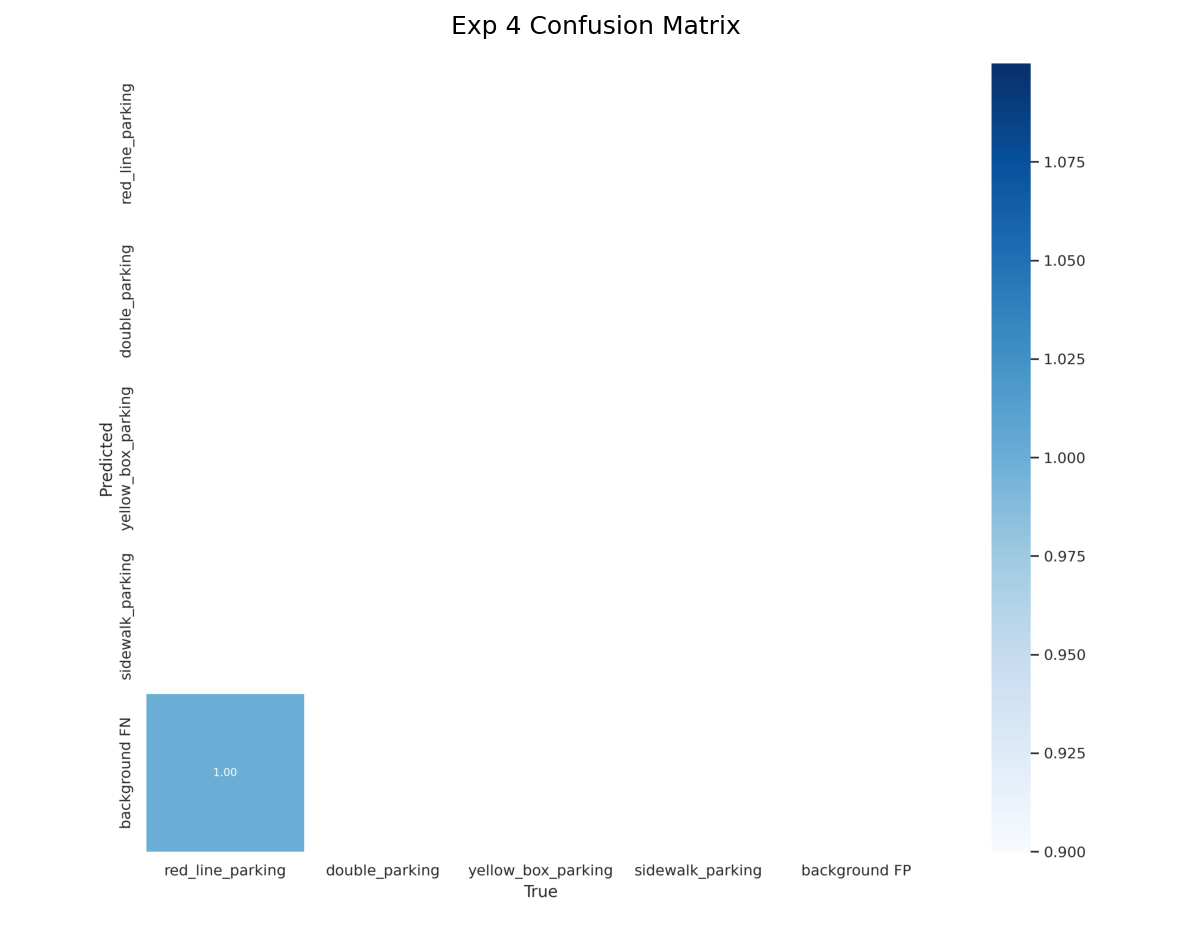

In [22]:
import glob
import matplotlib.pyplot as plt
import cv2

# 顯示 Exp 4 訓練曲線與混淆矩陣
exp4_results = "runs/train/exp4_yolov7_tiny_tuned/results.png"
exp4_cm = "runs/train/exp4_yolov7_tiny_tuned/confusion_matrix.png"

if os.path.exists(exp4_results):
    plt.figure(figsize=(14, 8), dpi=150)
    img = cv2.imread(exp4_results)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Exp 4 Training Results & Metrics")
    plt.axis("off")
    plt.show()

if os.path.exists(exp4_cm):
    plt.figure(figsize=(10, 8), dpi=150)
    img = cv2.imread(exp4_cm)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Exp 4 Confusion Matrix")
    plt.axis("off")
    plt.show()

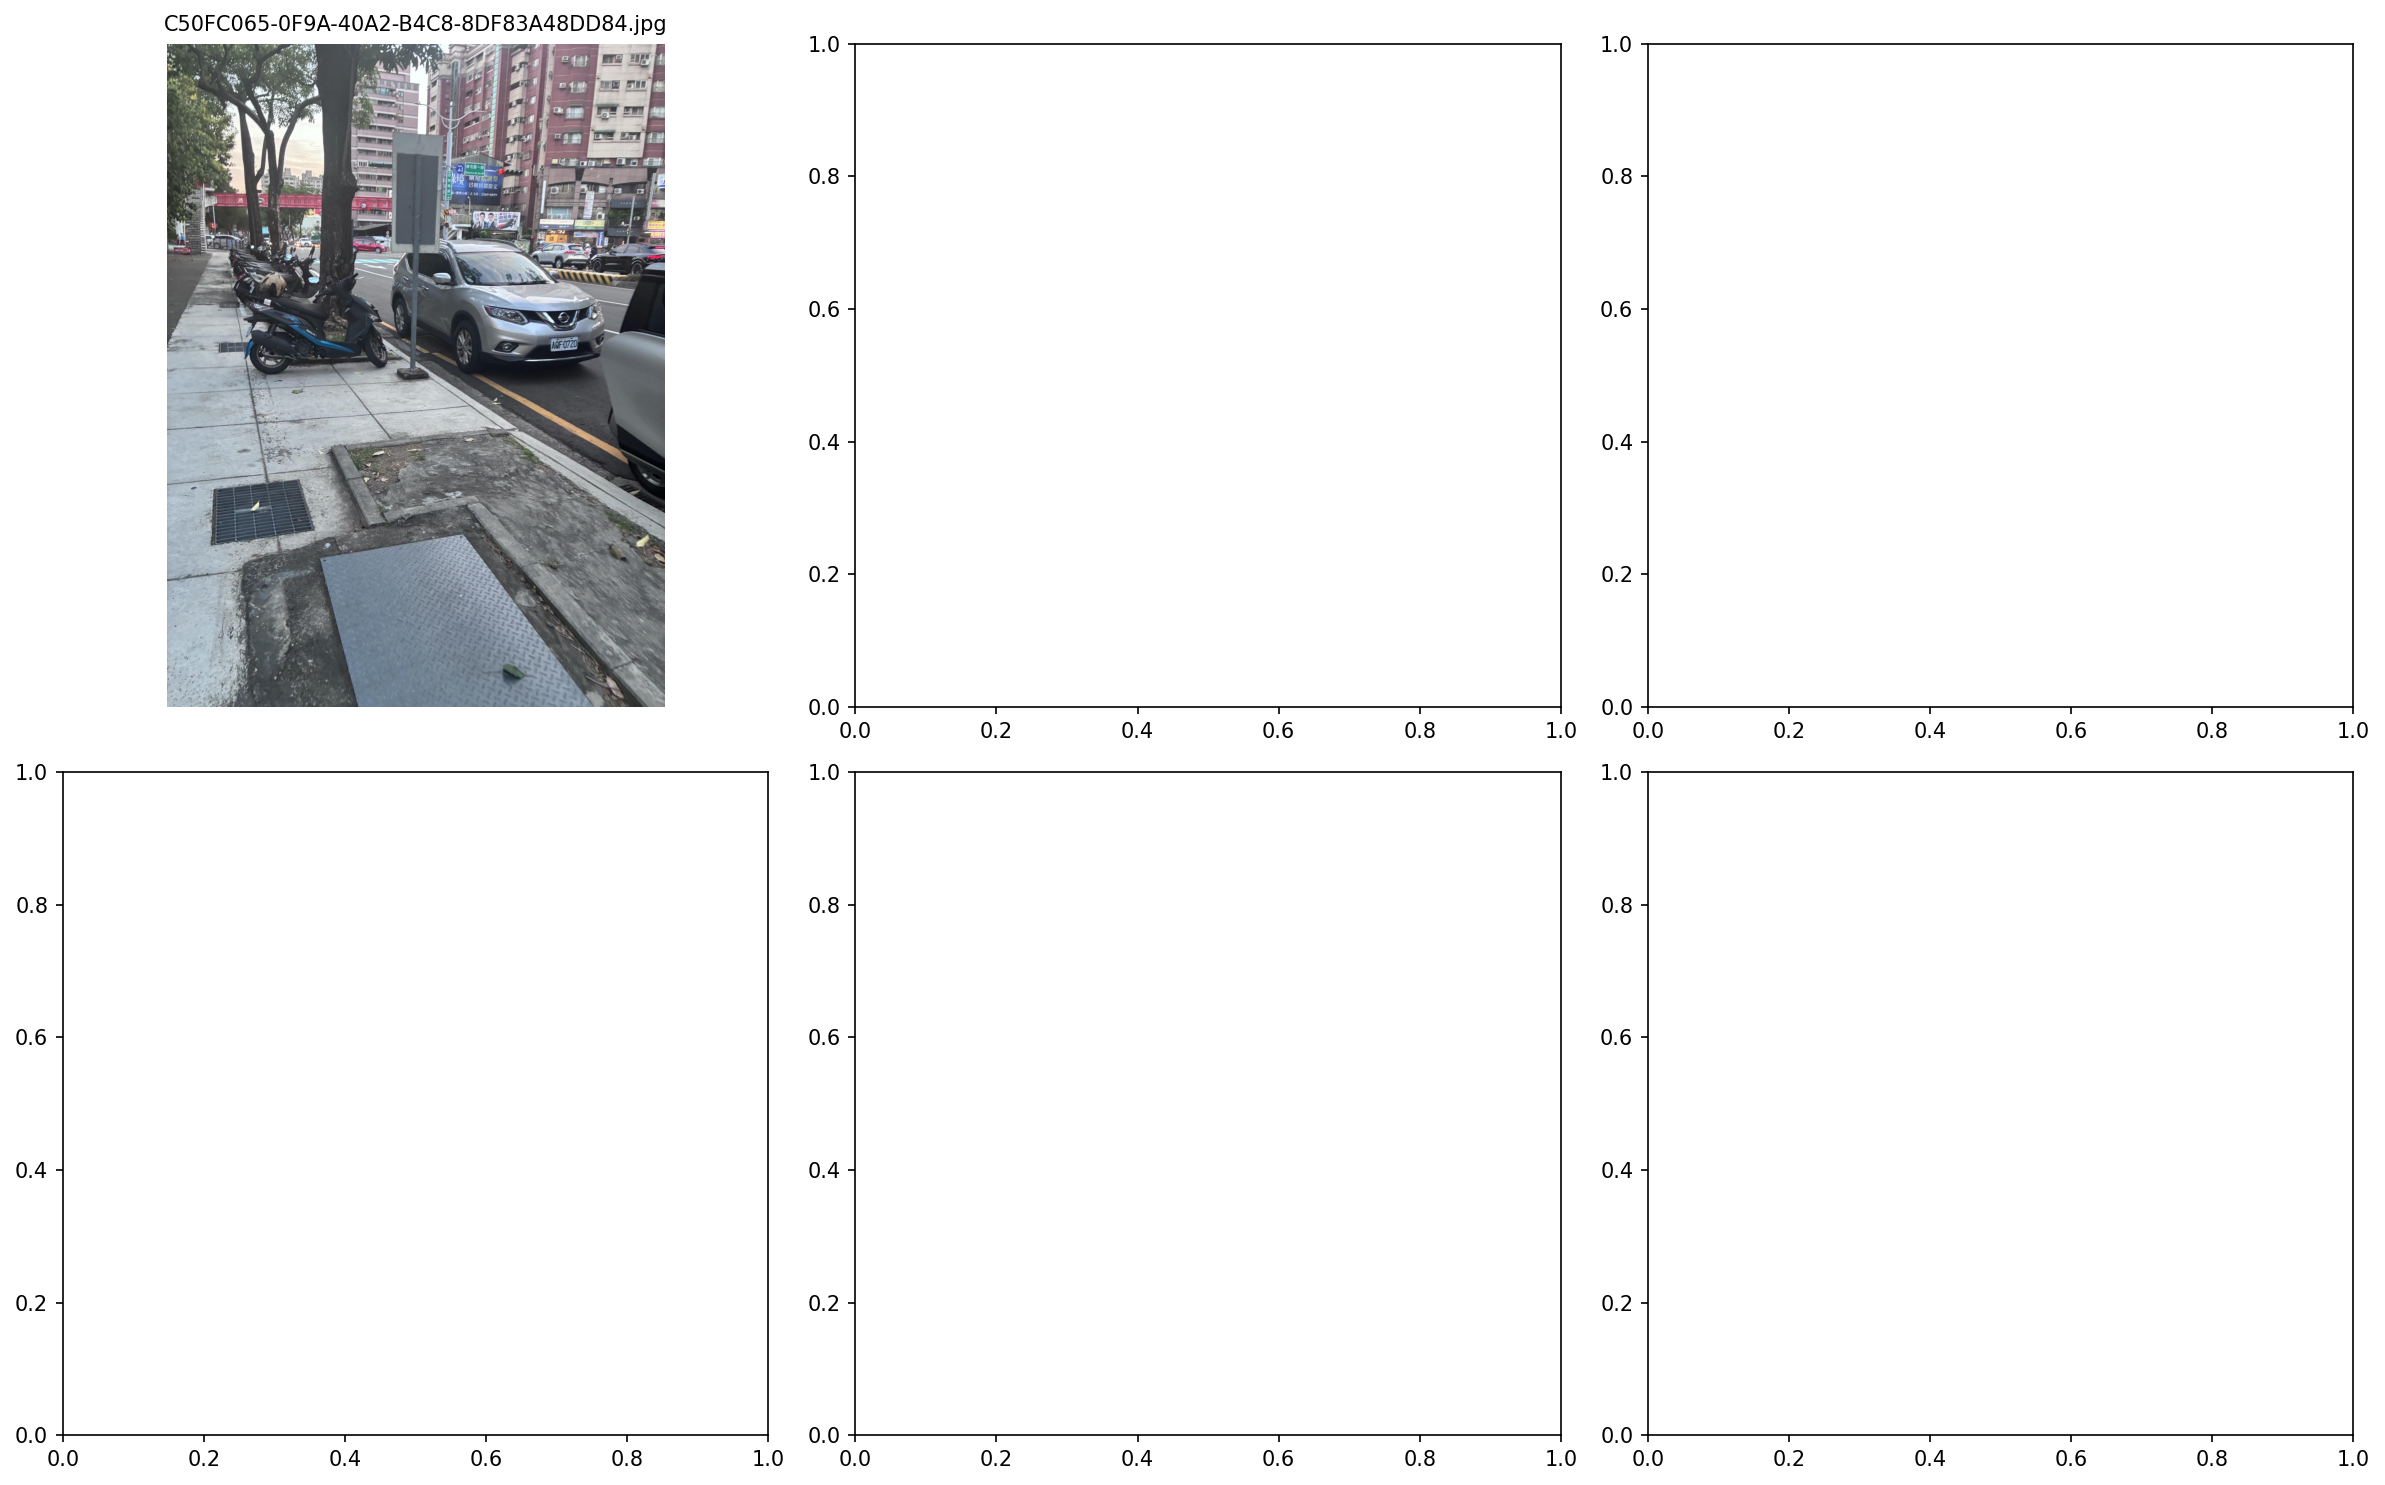

In [23]:
# 繪製推論成果抽樣網格 (2x3)
det_images = glob.glob("runs/detect/detect_test_images/*.jpg")[:6]
if det_images:
    fig, axes = plt.subplots(2, 3, figsize=(16, 10), dpi=150)
    axes = axes.flatten()
    for i, img_path in enumerate(det_images):
        img = cv2.imread(img_path)
        axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i].set_title(os.path.basename(img_path), fontsize=10)
        axes[i].axis("off")
    plt.tight_layout()
    plt.show()

# **Step 9: 儲存權重與期末成果打包 (Save to Google Drive)**
自動將各組權重、指標圖表與推論成果打包壓縮至 Google Drive 備份，供期末報告投影片使用。

In [24]:
!mkdir -p /content/drive/MyDrive/NCHU_YOLO_Project/results
!cp runs/train/exp4_yolov7_tiny_tuned/weights/best.pt /content/drive/MyDrive/NCHU_YOLO_Project/results/best_model_exp4.pt

# 打包所有實驗圖表與推論成果
!zip -r /content/drive/MyDrive/NCHU_YOLO_Project/results_summary.zip \
  runs/train/exp*/results.png \
  runs/train/exp*/confusion_matrix.png \
  runs/train/exp*/weights/best.pt \
  runs/detect/

print("🎉 實驗指標與權重已成功備份至 Google Drive (NCHU_YOLO_Project/)！")

  adding: runs/train/exp1_yolov7_tiny_baseline3/results.png (deflated 10%)
  adding: runs/train/exp2_yolov7_base_scale/results.png (deflated 9%)
  adding: runs/train/exp3_yolov7_tiny_100ep/results.png (deflated 9%)
  adding: runs/train/exp4_yolov7_tiny_tuned/results.png (deflated 10%)
  adding: runs/train/exp1_yolov7_tiny_baseline3/confusion_matrix.png (deflated 28%)
  adding: runs/train/exp2_yolov7_base_scale/confusion_matrix.png (deflated 28%)
  adding: runs/train/exp3_yolov7_tiny_100ep/confusion_matrix.png (deflated 28%)
  adding: runs/train/exp4_yolov7_tiny_tuned/confusion_matrix.png (deflated 28%)
  adding: runs/train/exp1_yolov7_tiny_baseline3/weights/best.pt (deflated 8%)
  adding: runs/train/exp2_yolov7_base_scale/weights/best.pt (deflated 8%)
  adding: runs/train/exp3_yolov7_tiny_100ep/weights/best.pt (deflated 8%)
  adding: runs/train/exp4_yolov7_tiny_tuned/weights/best.pt (deflated 8%)
  adding: runs/detect/ (stored 0%)
  adding: runs/detect/detect_test_images/ (stored 0%)
 